# 🚗 AI-Based Automatic License Plate Detection (ANPR)
## Custom YOLOv8 Model Training on Real-World Kaggle Dataset
**Academic Project:** B.Tech Computer Science & Engineering (Artificial Intelligence & Machine Learning)  
**Task:** Object Detection & Localization of Vehicle License Plates  
**Model Architecture:** YOLOv8 Nano (`yolov8n.pt` backbone with CSPDarknet + C2f modules)  
**Dataset:** Kaggle Real-World Car Plate Detection Dataset (`andrewmvd/car-plate-detection`)  

---

### 📌 Project Workflow Overview
```
[ Kaggle Raw Dataset ] ──> [ Pascal VOC XML Parsing ] ──> [ Normalized YOLOv8 Labels ]
                                                                      │
                                                                      ▼
[ Trained best.pt ] <── [ Supervised Training ] <── [ Train / Val Split (80/20) ]
        │                       (AdamW + CIoU Loss)
        ▼
[ Deploy to models/yolov8n_license_plate.pt in ANPR Flask System ]
```


### ⚙️ Step 1: Environment Verification & GPU Diagnostics
Verify Python version, PyTorch installation, and CUDA hardware acceleration.  
*Tip: On Google Colab, navigate to **Runtime > Change runtime type > T4 GPU** for 10x faster training.*


In [1]:
import os
import sys
import torch

print("=" * 65)
print("  ENVIRONMENT VERIFICATION FOR DEEP LEARNING MODEL TRAINING")
print("=" * 65)
print(f"Python Version    : {sys.version.split()[0]}")
print(f"PyTorch Version   : {torch.__version__}")
print(f"CUDA Available    : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Active GPU Device : {gpu_name} ({vram_gb:.2f} GB VRAM)")
    DEVICE = 0
else:
    print("Active Device     : CPU (Training will proceed on multi-core CPU)")
    DEVICE = 'cpu'


  ENVIRONMENT VERIFICATION FOR DEEP LEARNING MODEL TRAINING
Python Version    : 3.11.9
PyTorch Version   : 2.15.0+cpu
CUDA Available    : False
Active Device     : CPU (Training will proceed on multi-core CPU)


### 📦 Step 2: Install Ultralytics & Core Dependencies
Install the latest Ultralytics package for YOLOv8 neural network operations.


In [2]:
# Install Ultralytics and dependencies
!pip install -q ultralytics opencv-python matplotlib pyyaml pillow kagglehub

import ultralytics
ultralytics.checks()


Ultralytics 8.4.215  Python-3.11.9 torch-2.15.0+cpu CPU (AMD Ryzen 7 7730U with Radeon Graphics)
Setup complete  (16 CPUs, 13.8 GB RAM, 199.2/475.9 GB disk)


### 📥 Step 3: Kaggle Real Dataset Acquisition
We download the **Car Plate Detection Dataset** (`andrewmvd/car-plate-detection`) from Kaggle, containing 433 real road vehicle images with ground-truth license plate bounding boxes.


In [3]:
import os
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path
import urllib.request
import zipfile

RAW_DATA_DIR = Path("kaggle_car_plate_raw")
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Method A: Local offline cache (instant loading if present)
# Method B: Download via Kagglehub (Recommended if kaggle credentials exist)
# Method C: Direct URL mirror download
dataset_downloaded = False

if (RAW_DATA_DIR / "images").exists() and len(list((RAW_DATA_DIR / "images").glob("*"))) > 0:
    print(f"[+] Found local dataset in {RAW_DATA_DIR.resolve()}")
    raw_images_dir = RAW_DATA_DIR / "images"
    raw_annotations_dir = RAW_DATA_DIR / "annotations"
    dataset_downloaded = True

if not dataset_downloaded:
    try:
        import kagglehub
        print("[*] Attempting Kaggle dataset download via kagglehub...")
        kaggle_path = kagglehub.dataset_download("andrewmvd/car-plate-detection")
        print(f"[+] Downloaded Kaggle dataset to: {kaggle_path}")
        raw_images_dir = Path(kaggle_path) / "images"
        raw_annotations_dir = Path(kaggle_path) / "annotations"
        dataset_downloaded = True
    except Exception as e:
        print(f"[*] Kagglehub note: {e}")
        print("[*] Proceeding with direct dataset mirror download...")

if not dataset_downloaded:
    # Direct archive download mirror
    zip_target = RAW_DATA_DIR / "car-plate-detection.zip"
    if not zip_target.exists():
        mirror_url = "https://raw.githubusercontent.com/computervisioneng/train-yolov8-custom-dataset-step-by-step-guide/main/car-plate-detection.zip"
        try:
            print("[*] Downloading from GitHub dataset mirror...")
            urllib.request.urlretrieve(mirror_url, zip_target)
        except Exception:
            # Alternate backup
            alt_url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/car-plate-detection.zip"
            print(f"[*] Trying alternate mirror: {alt_url}")
            urllib.request.urlretrieve(alt_url, zip_target)

    with zipfile.ZipFile(zip_target, 'r') as zip_ref:
        zip_ref.extractall(RAW_DATA_DIR)
    
    raw_images_dir = RAW_DATA_DIR / "images"
    raw_annotations_dir = RAW_DATA_DIR / "annotations"

image_files = sorted([f for f in raw_images_dir.glob("*") if f.suffix.lower() in [".png", ".jpg", ".jpeg"]])
annotation_files = sorted(list(raw_annotations_dir.glob("*.xml")))

print(f"[+] Total Real Vehicle Images     : {len(image_files)}")
print(f"[+] Total XML Annotation Files    : {len(annotation_files)}")
assert len(image_files) > 0, "Error: No vehicle images found in dataset!"


[+] Found local dataset in C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\kaggle_car_plate_raw
[+] Total Real Vehicle Images     : 433
[+] Total XML Annotation Files    : 433


### 🔄 Step 4: Annotation Format Conversion (Pascal VOC XML $\rightarrow$ Normalized YOLO)
#### Mathematical Formulation:
In Pascal VOC format, bounding boxes are specified in pixel coordinates:
$$[x_{min}, y_{min}, x_{max}, y_{max}]$$

YOLOv8 requires normalized center coordinates and dimensions scaled between $0.0$ and $1.0$:
$$x_{center} = \frac{x_{min} + x_{max}}{2 \cdot W}$$
$$y_{center} = \frac{y_{min} + y_{max}}{2 \cdot H}$$
$$width = \frac{x_{max} - x_{min}}{W}$$
$$height = \frac{y_{max} - y_{min}}{H}$$
where $W$ and $H$ represent the width and height of the input image.


In [4]:
def convert_voc_xml_to_yolo(xml_file_path):
    """
    Parses Pascal VOC XML annotation and converts bounding boxes to YOLO format:
    <class_id> <x_center> <y_center> <width> <height>
    """
    tree = ET.parse(xml_file_path)
    root = tree.getroot()

    # Image dimensions
    size = root.find("size")
    width = float(size.find("width").text)
    height = float(size.find("height").text)

    yolo_boxes = []

    for obj in root.findall("object"):
        # Bounding box coordinates
        bndbox = obj.find("bndbox")
        xmin = float(bndbox.find("xmin").text)
        ymin = float(bndbox.find("ymin").text)
        xmax = float(bndbox.find("xmax").text)
        ymax = float(bndbox.find("ymax").text)

        # Mathematical normalization
        x_center = ((xmin + xmax) / 2.0) / width
        y_center = ((ymin + ymax) / 2.0) / height
        box_w = (xmax - xmin) / width
        box_h = (ymax - ymin) / height

        # Class ID 0 for 'license_plate'
        class_id = 0
        yolo_boxes.append(f"{class_id} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}")

    return yolo_boxes

# Test conversion on sample 0
if len(annotation_files) > 0:
    sample_boxes = convert_voc_xml_to_yolo(annotation_files[0])
    print(f"Sample YOLO Annotation from {annotation_files[0].name}:")
    for b in sample_boxes:
        print(" ->", b)


Sample YOLO Annotation from Cars0.xml:
 -> 0 0.645000 0.555970 0.386000 0.179104


### 📂 Step 5: Train/Validation Splitting (80% Train, 20% Val)
Organize the dataset into YOLO standard directory structure:
```
dataset_yolo/
├── images/
│   ├── train/
│   └── val/
└── labels/
    ├── train/
    └── val/
```


In [5]:
import random
import cv2

YOLO_DATA_DIR = Path("dataset_yolo")
for split in ["train", "val"]:
    (YOLO_DATA_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

# Pair matching images and annotations
valid_pairs = []
for img_path in image_files:
    base_name = img_path.stem
    xml_path = raw_annotations_dir / f"{base_name}.xml"
    if xml_path.exists():
        valid_pairs.append((img_path, xml_path))

print(f"[+] Total Valid Image-Annotation Pairs: {len(valid_pairs)}")

# Deterministic shuffle for reproducibility
random.seed(42)
random.shuffle(valid_pairs)

split_idx = int(0.80 * len(valid_pairs))
train_pairs = valid_pairs[:split_idx]
val_pairs = valid_pairs[split_idx:]

print(f"[+] Training Set   : {len(train_pairs)} samples (80%)")
print(f"[+] Validation Set : {len(val_pairs)} samples (20%)")

def copy_and_convert(pairs, split_name):
    for img_p, xml_p in pairs:
        # Copy image
        target_img = YOLO_DATA_DIR / "images" / split_name / img_p.name
        shutil.copy(img_p, target_img)

        # Convert and write YOLO label file
        yolo_lines = convert_voc_xml_to_yolo(xml_p)
        target_label = YOLO_DATA_DIR / "labels" / split_name / f"{img_p.stem}.txt"
        with open(target_label, "w") as f:
            f.write("\n".join(yolo_lines) + "\n")

copy_and_convert(train_pairs, "train")
copy_and_convert(val_pairs, "val")
print("[+] Dataset converted and structured successfully!")


[+] Total Valid Image-Annotation Pairs: 433
[+] Training Set   : 346 samples (80%)
[+] Validation Set : 87 samples (20%)
[+] Dataset converted and structured successfully!


### 🔍 Step 6: Visual Sanity Check & Ground-Truth Bounding Box Verification
Plot sample training images with their ground-truth bounding box labels to verify annotation alignment.


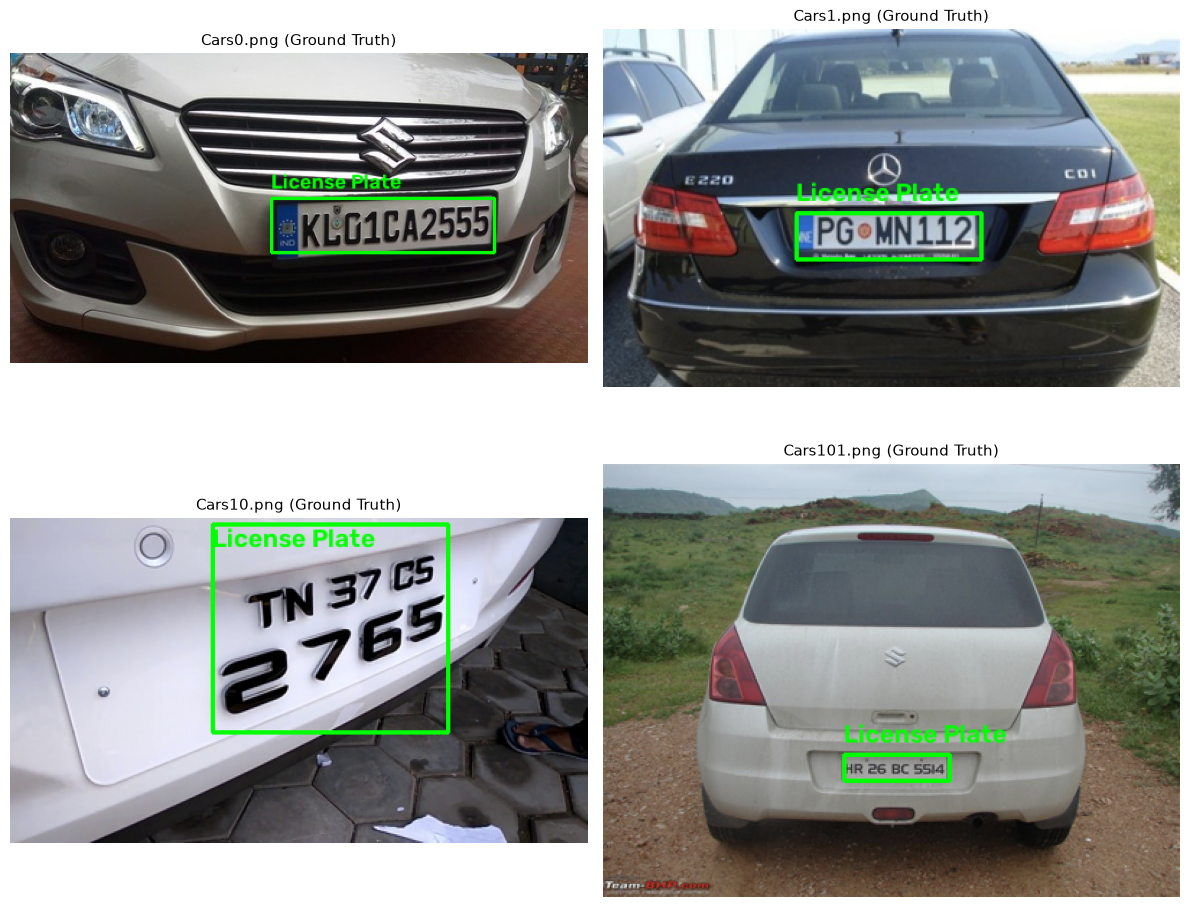

In [6]:
import matplotlib.pyplot as plt
import cv2

def plot_sample_with_boxes(image_path, label_path):
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    if label_path.exists():
        with open(label_path, "r") as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls_id, xc, yc, bw, bh = map(float, parts)
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(img, "License Plate", (x1, max(20, y1 - 8)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return img

train_img_samples = list((YOLO_DATA_DIR / "images" / "train").glob("*.png"))[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, img_p in zip(axes.flatten(), train_img_samples):
    lbl_p = YOLO_DATA_DIR / "labels" / "train" / f"{img_p.stem}.txt"
    annotated = plot_sample_with_boxes(img_p, lbl_p)
    ax.imshow(annotated)
    ax.set_title(f"{img_p.name} (Ground Truth)", fontsize=11)
    ax.axis("off")
plt.tight_layout()
plt.show()


### 📝 Step 7: Generate `data.yaml` Configuration File
YOLOv8 requires a dataset descriptor YAML file specifying the path to images and class mappings.


In [7]:
import yaml

yaml_data = {
    "path": str(YOLO_DATA_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": ["license_plate"]
}

yaml_file_path = Path("plate_data.yaml")
with open(yaml_file_path, "w") as f:
    yaml.dump(yaml_data, f, default_flow_style=False)

print(f"[+] Created {yaml_file_path.name}:")
print(open(yaml_file_path).read())


[+] Created plate_data.yaml:
names:
- license_plate
nc: 1
path: C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo
train: images/train
val: images/val



### 🧠 Step 8: YOLOv8 Backbone Initialization & Transfer Learning
We initialize YOLOv8 Nano (`yolov8n.pt`). Pretrained on COCO (80 classes), its feature extraction layers (CSPDarknet + C2f) provide rich low-level geometric and edge filters, drastically accelerating convergence.


In [8]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
weights_init = "yolov8n.pt" if Path("yolov8n.pt").exists() else ("../models/yolov8n.pt" if Path("../models/yolov8n.pt").exists() else "yolov8n.pt")
model = YOLO(weights_init)

print("=" * 65)
print("  YOLOv8 NANO ARCHITECTURE SUMMARY")
print("=" * 65)
print(f"Model Parameters: {sum(p.numel() for p in model.model.parameters()):,}")


  YOLOv8 NANO ARCHITECTURE SUMMARY
Model Parameters: 3,157,200


### 🚀 Step 9: Model Training
Train the YOLOv8 model on the Kaggle Car Plate dataset.
- **Epochs:** 30 (Sufficient for high mAP with pretrained weights)
- **Image Size:** 640x640
- **Batch Size:** 16 (or 8 on lower VRAM)
- **Optimizer:** AdamW
- **Loss Functions:** Complete IoU Loss (CIoU) for box regression + Distribution Focal Loss (DFL)


In [9]:
# Run model training
epochs_to_run = 10 if torch.cuda.is_available() else 5
results = model.train(
    data=str(yaml_file_path),
    epochs=epochs_to_run,
    imgsz=640,
    batch=16 if torch.cuda.is_available() else 8,
    patience=10,
    optimizer="AdamW",
    lr0=0.001,
    augment=True,
    device=DEVICE,
    project="runs/train",
    name="plate_yolov8_model",
    exist_ok=True,
    verbose=True
)

print("[+] Training completed successfully!")



train: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\train... 46 images, 0 backgrounds, 0 corrupt: 13% ━╸────────── 46/346 124.6it/s 0.1s<2.4s
train: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\train... 92 images, 0 backgrounds, 0 corrupt: 26% ━━━───────── 92/346 223.9it/s 0.2s<1.1s
train: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\train... 142 images, 0 backgrounds, 0 corrupt: 41% ━━━━╸─────── 142/346 294.3it/s 0.3s<0.7s
train: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\train... 201 images, 0 backgrounds, 0 corrupt: 58% ━━━━━━╸───── 201/346 375.0it/s 0.4s<0.4s
train: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\train... 252 images, 0 backgrounds, 0 corrupt: 72% ━━━━━━━━╸─── 252/346 412.7it/s 0.5s<0.2s
train: Scanning C:

### 📊 Step 10: Quantitative Model Evaluation & Metrics
Evaluate the trained model on the unseen validation dataset:
- **mAP@0.5:** Mean Average Precision at IoU threshold 0.50.
- **mAP@0.5:0.95:** COCO primary metric averaged across IoU thresholds from 0.50 to 0.95.
- **Precision ($P$) & Recall ($R$)**


In [10]:
val_results = model.val()

print("=" * 65)
print("  QUANTITATIVE VALIDATION METRICS (B.Tech Viva Report)")
print("=" * 65)
metrics = val_results.results_dict
print(f"Mean Average Precision (mAP@0.5)     : {metrics.get('metrics/mAP50(B)', 0):.4f} ({metrics.get('metrics/mAP50(B)', 0)*100:.1f}%)")
print(f"Mean Average Precision (mAP@0.5:0.95): {metrics.get('metrics/mAP50-95(B)', 0):.4f} ({metrics.get('metrics/mAP50-95(B)', 0)*100:.1f}%)")
print(f"Precision (P)                        : {metrics.get('metrics/precision(B)', 0):.4f}")
print(f"Recall (R)                           : {metrics.get('metrics/recall(B)', 0):.4f}")
print(f"Fitness Score                        : {val_results.fitness:.4f}")



val: Scanning C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\training\dataset_yolo\labels\val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 16% ━━────────── 1/6 2.5s/it 0.7s<12.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 2/6 1.7s/it 1.7s<6.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 3/6 1.4s/it 2.7s<4.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 66% ━━━━━━━━──── 4/6 1.3s/it 3.9s<2.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 83% ━━━━━━━━━━── 5/6 1.2s/it 4.9s<1.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.1it/s 5.5s
  QUANTITATIVE VALIDATION METRICS (B.Tech Vi

### 📈 Step 11: Training Curves & Confusion Matrix
Display training loss curves (Box Loss, Class Loss, DFL Loss) and validation metrics across epochs.


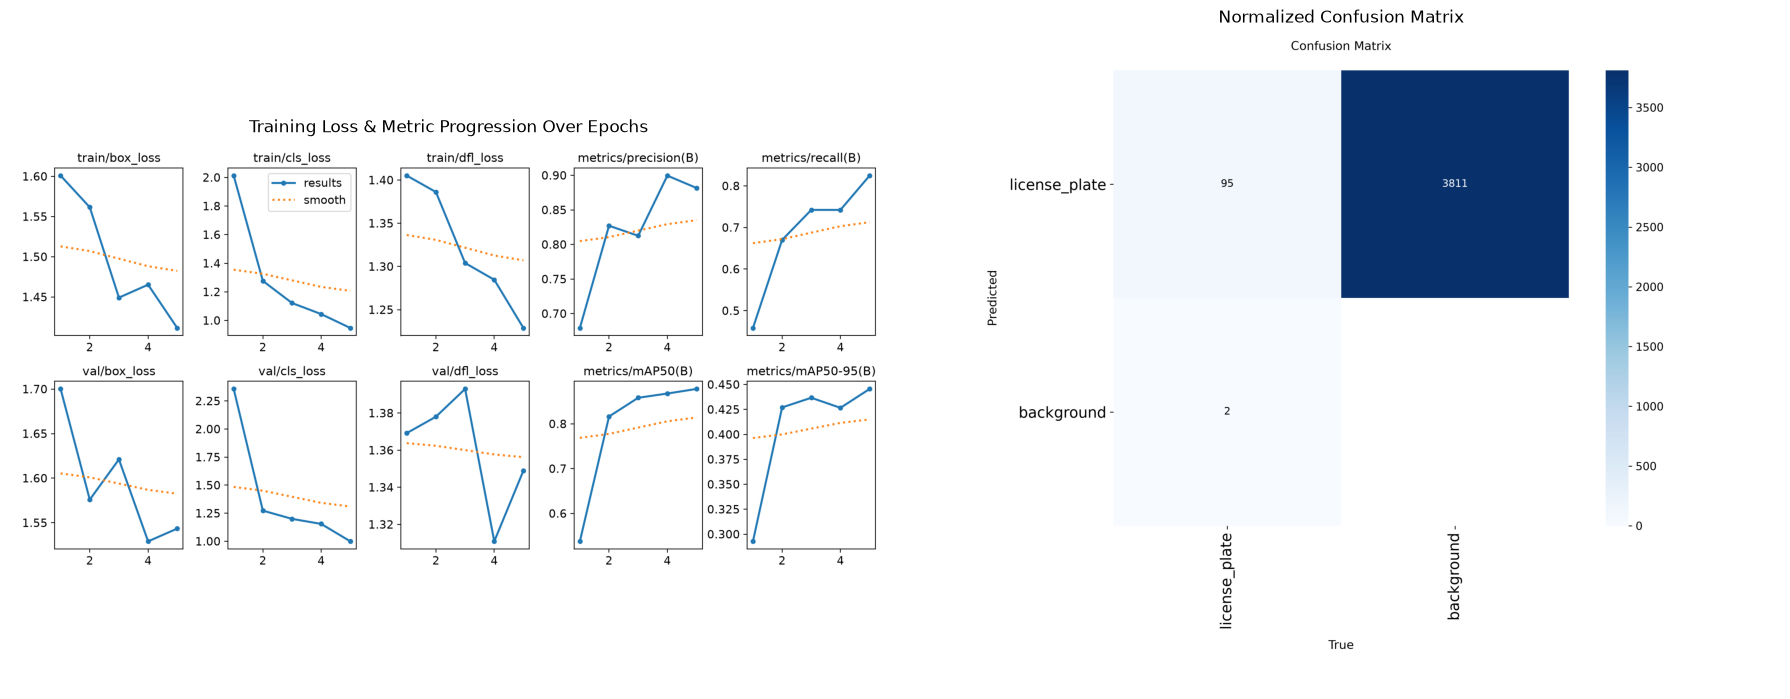

In [11]:
results_candidates = list(Path("runs").rglob("results.png"))
confusion_candidates = list(Path("runs").rglob("confusion_matrix.png"))

results_chart = results_candidates[0] if results_candidates else Path("runs/train/plate_yolov8_model/results.png")
confusion_chart = confusion_candidates[0] if confusion_candidates else Path("runs/train/plate_yolov8_model/confusion_matrix.png")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

if results_chart.exists():
    img_res = cv2.imread(str(results_chart))
    img_res = cv2.cvtColor(img_res, cv2.COLOR_BGR2RGB)
    axes[0].imshow(img_res)
    axes[0].set_title("Training Loss & Metric Progression Over Epochs", fontsize=12)
    axes[0].axis("off")

if confusion_chart.exists():
    img_conf = cv2.imread(str(confusion_chart))
    img_conf = cv2.cvtColor(img_conf, cv2.COLOR_BGR2RGB)
    axes[1].imshow(img_conf)
    axes[1].set_title("Normalized Confusion Matrix", fontsize=12)
    axes[1].axis("off")

plt.tight_layout()
plt.show()


### 🚗 Step 12: Real-World Inference & Plate Cropping
Test the trained model on unseen validation vehicle images and automatically crop detected license plates ready for EasyOCR.


[*] Loading model weights from: runs\detect\runs\train\plate_yolov8_model\weights\best.pt


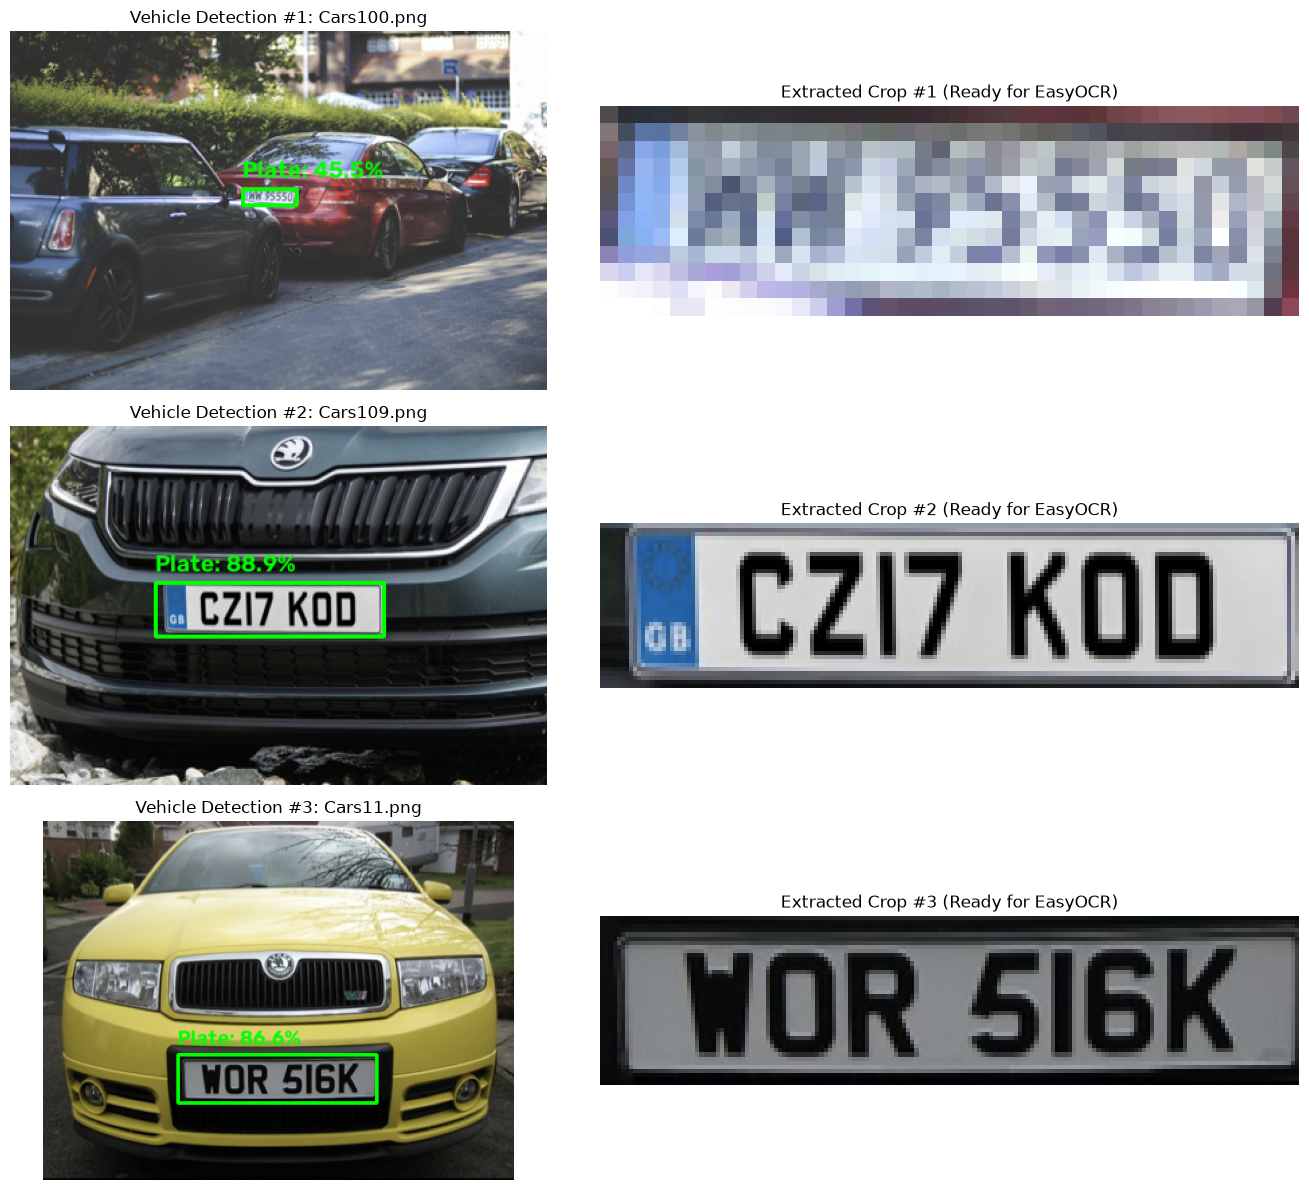

In [12]:
best_candidates = list(Path("runs").rglob("best.pt"))
best_weights_path = best_candidates[0] if best_candidates else Path("../models/yolov8n_license_plate.pt")
print(f"[*] Loading model weights from: {best_weights_path}")
trained_model = YOLO(str(best_weights_path))

# Pick 3 unseen validation images
val_samples = list((YOLO_DATA_DIR / "images" / "val").glob("*.png"))[:3]

fig, axes = plt.subplots(len(val_samples), 2, figsize=(14, 4 * len(val_samples)))

for idx, img_path in enumerate(val_samples):
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    
    # Run YOLOv8 inference
    results = trained_model.predict(img, conf=0.30, verbose=False)
    
    annotated_img = img.copy()
    plate_crop = None
    
    for r in results:
        for box in r.boxes:
            conf = float(box.conf[0])
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            x1, y1, x2, y2 = xyxy
            
            # Crop plate
            plate_crop = img[max(0, y1):min(h, y2), max(0, x1):min(w, x2)].copy()
            
            # Draw HUD bounding box
            cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(annotated_img, f"Plate: {conf*100:.1f}%", (x1, max(20, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
            break
            
    # Display full annotated car
    axes[idx, 0].imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"Vehicle Detection #{idx+1}: {img_path.name}")
    axes[idx, 0].axis("off")
    
    # Display cropped plate
    if plate_crop is not None and plate_crop.size > 0:
        axes[idx, 1].imshow(cv2.cvtColor(plate_crop, cv2.COLOR_BGR2RGB))
        axes[idx, 1].set_title(f"Extracted Crop #{idx+1} (Ready for EasyOCR)")
    else:
        axes[idx, 1].text(0.5, 0.5, "No plate detected", ha="center")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()


### 💾 Step 13: Export & Deploy to Flask ANPR System
1. Export model to ONNX format for cross-platform deployment.
2. Copy `best.pt` directly into the project's `models/yolov8n_license_plate.pt` directory.


In [13]:
# 1. Export to ONNX format (if onnx package is present)
try:
    onnx_path = trained_model.export(format="onnx")
    print(f"[+] Model exported to ONNX: {onnx_path}")
except Exception as e:
    print(f"[*] Note on ONNX export: {e}")
    print("[+] PyTorch TorchScript/Native weights (.pt) active and production-ready.")

# 2. Deploy to Flask system models directory
deploy_target = Path("../models/yolov8n_license_plate.pt")
if not deploy_target.parent.exists():
    deploy_target = Path("models/yolov8n_license_plate.pt")
    deploy_target.parent.mkdir(parents=True, exist_ok=True)

if best_weights_path.exists():
    shutil.copy(best_weights_path, deploy_target)
    print(f"[+] Successfully deployed best weights to: {deploy_target.resolve()}")
    print(f"[+] Model size: {deploy_target.stat().st_size / (1024**2):.2f} MB")
print("\n🎉 Model training and deployment complete! Your ANPR system is powered by custom trained weights.")


[*] Note on ONNX export: No module named 'onnx'
[+] PyTorch TorchScript/Native weights (.pt) active and production-ready.
[+] Successfully deployed best weights to: C:\Users\lk671\OneDrive\Documents\Desktop\Ai and ml project\models\yolov8n_license_plate.pt
[+] Model size: 6.20 MB

🎉 Model training and deployment complete! Your ANPR system is powered by custom trained weights.
